# 01 — Dataset Exploration & Audit (Way2Home: AI Analisis Kendala)

**Tujuan:** mengaudit seluruh dataset sumber **sebelum** harmonisasi dan training: struktur file, kolom, tipe data, jumlah baris, missing values, duplikasi, distribusi target, asal-usul data, kebocoran label (*leakage*), serta kesetaraan makna terhadap input `ai-kendala.service.ts`.

Notebook ini **read-only**: tidak ada data yang diubah. Pembersihan dan penggabungan dilakukan di `02_data_harmonization.ipynb`.

**Dataset yang diaudit** (semua di `data/raw/`):

| # | Sumber | File |
|---|---|---|
| 1 | Causes of Delays in Construction Projects — Aceh (Mendeley) | `Dataset_1.xlsx` |
| 2 | Simulated Project Risk & Earned Value (Mendeley) — fitur mentah | `project_risk_raw_dataset.csv` |
| 3 | Simulated Project Risk & EV — ringkasan | `project_delay_cost_overrun_summary_final.csv.xlsx` |
| 4 | Simulated Project Risk & EV — deret waktu | `simulated_project_ev_metrics_final.csv.xlsx` |
| 5 | Construction Project Delay Risk Prediction (GitHub) | `construction_projects.csv` |
| 6 | BIM AI Civil Engineering Dataset (GitHub) | `bim_ai_civil_engineering_dataset.csv` (+ notebook asli) |
| 7 | Construction Delay Prediction (GitHub, synthetic) | `synthetic_construction_projects.csv` |
| 8 | RCPLIB (diunggah sebagai pengganti DSLIB/PSLIB) | `RCPLIB__Parameters_and_BKS_.xlsx` |

Skrip pembangkit dataset #3–#4 (`simulate_project_ev_metrics.py.txt`) juga diperiksa.

In [1]:
import warnings, io, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kstest, chi2_contingency, f_oneway
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 80)

RAW = Path("../data/raw")
REPORTS = Path("../reports"); REPORTS.mkdir(parents=True, exist_ok=True)
SEED = 42

# Palet grafik: satu hue (biru) untuk satu seri, ramp biru untuk kelas ordinal LOW/MEDIUM/HIGH
C_MAIN = "#2a78d6"
C_ORD = {"Low": "#86b6ef", "Medium": "#3987e5", "High": "#184f95"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})

def profile(df, name):
    # Ringkasan struktur: dimensi, duplikasi, tipe, missing, jumlah nilai unik
    print(f"=== {name}: {df.shape[0]:,} baris × {df.shape[1]} kolom | duplikat baris: {df.duplicated().sum()}")
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(1),
                         "n_unique": df.nunique()})
    return info

def read_csv_inside_xlsx(path):
    # Beberapa file .xlsx sebenarnya berisi teks CSV di satu kolom Excel
    lines = pd.read_excel(path, header=None)[0].astype(str)
    return pd.read_csv(io.StringIO("\n".join(lines)))

audit_rows = []   # dikumpulkan per dataset, disimpan di akhir

## 0. Inventaris file

In [2]:
inv = pd.DataFrame([{"file": p.name, "size_KB": round(p.stat().st_size / 1024, 1)}
                    for p in sorted(RAW.iterdir()) if p.is_file()])
display(inv)

                                                 file  size_KB
0                                      Dataset_1.xlsx     30.2
1                    RCPLIB__Parameters_and_BKS_.xlsx  41341.4
2                                   RCPLIB_readme.rtf     22.9
3                                RCPSP_DataFormat.pdf    134.1
4                                      attachment.txt      7.6
5                bim_ai_civil_engineering_dataset.csv    350.1
6                 bim_civil_engineering_dataset.ipynb   1218.7
7                           construction_projects.csv    323.3
8   project_delay_cost_overrun_summary_final.csv.xlsx    164.3
9                        project_risk_raw_dataset.csv   1196.1
10                 simulate_project_ev_metrics.py.txt     15.6
11        simulated_project_ev_metrics_final.csv.xlsx   7052.8
12                synthetic_construction_projects.csv     78.6


## 1. Aceh — Causes of Delays in Construction Projects (empiris, survei)

Sumber: Rauzana & Dharma (2022), *PLOS ONE* 17(1): e0263337; data: Mendeley DOI 10.17632/2wckhrzz5j.1.
Responden adalah 68 manajer proyek kontraktor di Provinsi Aceh. Skala Likert 1–5 mengukur **tingkat pengaruh** faktor terhadap keterlambatan (5 = sangat tinggi, 1 = sangat rendah).

File Excel tidak memiliki header standar: kode item ada di baris ke-10 dan data mulai baris ke-11.

In [3]:
x = pd.read_excel(RAW / "Dataset_1.xlsx", header=None)
print("Ukuran sheet mentah:", x.shape)
header_row = 9
cols = ["Responden"] + list(x.iloc[header_row, 3:])
aceh = x.iloc[header_row + 1:, 2:].copy()
aceh.columns = cols
aceh = aceh.dropna(how="all")
aceh = aceh[pd.to_numeric(aceh["Responden"], errors="coerce").notna()].apply(pd.to_numeric)
info = profile(aceh, "Aceh survey")
items = aceh.drop(columns="Responden")
print("Rentang nilai Likert:", items.min().min(), "–", items.max().max())
print("Total missing:", int(items.isna().sum().sum()))
print("Responden duplikat (jawaban identik):", items.duplicated().sum())
display(aceh.head())

Ukuran sheet mentah: (78, 67)
=== Aceh survey: 68 baris × 65 kolom | duplikat baris: 0
Rentang nilai Likert: 2 – 5
Total missing: 0
Responden duplikat (jawaban identik): 0
    Responden  X1.1  X1.2  X1.3  X1.4  X1.5  X1.6  X1.7  X1.8  X1.9  X2.1  X2.2  X2.3  X3.1  X3.2  X3.3  X3.4  X4.1  X4.2  X4.3  X4.4  X4.5  X5.1  X5.2  X5.3  X5.4  X5.5  X5.6  X5.7  X5.8  X6.1  X6.2  X6.3  X6.4  X7.1  X7.2  X7.3  X7.4  X7.5  X7.6  X7.7  X7.8  X8.1  X8.2  X8.3  X8.4  X8.5  X8.6  X9.1  X9.2  X9.3  X9.4  X9.5  X9.6  X10.1  X10.2  X10.3  X10.4  X10.5  X10.6  X10.7  Y1  Y2  Y3  Y4
10          1     5     5     5     5     5     5     5     5     5     4     5     5     4     4     4     4     4     4     4     3     3     4     5     5     5     5     5     5     5     5     5     5     5     4     4     4     4     4     4     4     4     3     5     5     4     5     5     4     4     4     4     4     4      5      5      5      5      5      5      5   4   5   5   5
11          2     5     5     5   

Label item diambil dari artikel PLOS ONE. **Y1–Y4 tidak dijelaskan** di artikel maupun halaman Mendeley, sehingga maknanya tidak boleh diasumsikan.

In [4]:
ACEH_GROUPS = {"X1": "Material", "X2": "Equipment", "X3": "Financial", "X4": "Environment",
               "X5": "Labour", "X6": "Implementation", "X7": "Management", "X8": "Political",
               "X9": "Criminal", "X10": "Project Manager"}
ACEH_ITEMS = {
 "X1.1": "Lack of construction materials", "X1.2": "Material changes in form, function and specifications",
 "X1.3": "Material delivery delay", "X1.4": "Material damage in storage", "X1.5": "Scarcity of materials",
 "X1.6": "Inaccuracy in ordering materials", "X1.7": "Inefficient use of materials",
 "X1.8": "Delayed material arrival", "X1.9": "Poor calculation of material requirements",
 "X2.1": "Equipment breakdown", "X2.2": "Lack of equipment", "X2.3": "Poor equipment productivity",
 "X3.1": "Poor financial condition during implementation", "X3.2": "Delay in the payment process by the owner",
 "X3.3": "No financial support from banks for additional working capital",
 "X3.4": "High operational costs and overhead by contractors",
 "X4.1": "Effect of weather on construction activities", "X4.2": "Poor environmental safety",
 "X4.3": "Geological problems on site", "X4.4": "Lack of communication between contractors and the community",
 "X4.5": "Difficult access for heavy equipment to the project site",
 "X5.1": "Shortage of labour", "X5.2": "Labour incapacity", "X5.3": "Owner's intervention",
 "X5.4": "Labour fatigue owing to overtime", "X5.5": "Lack of awareness of workers on OSH",
 "X5.6": "Replacement of new workers", "X5.7": "Labour absenteeism rate", "X5.8": "Lack of workforce motivation",
 "X6.1": "Licensing delay", "X6.2": "There is a design change", "X6.3": "Design errors by planners",
 "X6.4": "There is additional work",
 "X7.1": "Weak time control system", "X7.2": "Poor arrangement of the sequence of activities",
 "X7.3": "No evaluation of job specifications before implementation", "X7.4": "No operating procedure for each job",
 "X7.5": "Error in understanding contract documents", "X7.6": "Poor OSH management",
 "X7.7": "Improper quality management procedures", "X7.8": "Error in using execution method",
 "X8.1": "Counterproductive print/electronic media news", "X8.2": "Lack of coordination between relevant agencies",
 "X8.3": "Inputs from other agencies causing design/technical changes", "X8.4": "Complicated permitting procedure",
 "X8.5": "Delay in the approval of the budget", "X8.6": "Rejection from certain mass organisations",
 "X9.1": "Loss of materials and equipment", "X9.2": "Damage to tools/materials/facilities by irresponsible parties",
 "X9.3": "Petty corruption by project workers", "X9.4": "Use of illegal substances by workers",
 "X9.5": "Extortion from outside", "X9.6": "Fights between workers",
 "X10.1": "Poor PM ability in selecting personnel", "X10.2": "Lack of PM experience in dividing tasks",
 "X10.3": "Lack of PM experience in scheduling", "X10.4": "Lack of PM communication with owner",
 "X10.5": "Poor communication between PM and team/sub-contractors", "X10.6": "PM does not encourage the whole team",
 "X10.7": "Lack of monitoring and control during implementation"}

x_cols = [c for c in items.columns if c.startswith("X")]
assert set(x_cols) == set(ACEH_ITEMS), "Kode item tidak cocok dengan artikel"

item_stats = pd.DataFrame({
    "group": [ACEH_GROUPS[c.split(".")[0]] for c in x_cols],
    "item": [ACEH_ITEMS[c] for c in x_cols],
    "mean": items[x_cols].mean().round(2).values,
    "mode": items[x_cols].mode().iloc[0].values,
    "share_4_5_%": ((items[x_cols] >= 4).mean() * 100).round(1).values}, index=x_cols)
print("10 item dengan rata-rata pengaruh tertinggi:")
display(item_stats.sort_values("mean", ascending=False).head(10))
print("Item dengan rata-rata terendah:")
display(item_stats.sort_values("mean").head(5))
print("Distribusi Y1–Y4 (makna tidak terdokumentasi):")
display(items[["Y1", "Y2", "Y3", "Y4"]].apply(lambda s: s.value_counts()).fillna(0).astype(int))

10 item dengan rata-rata pengaruh tertinggi:
               group                                                         item  mean  mode  share_4_5_%
X8.5       Political                          Delay in the approval of the budget  4.81   5.0        100.0
X3.2       Financial                    Delay in the payment process by the owner  4.69   5.0        100.0
X8.6       Political                    Rejection from certain mass organisations  4.68   5.0        100.0
X3.1       Financial               Poor financial condition during implementation  4.66   5.0        100.0
X3.4       Financial           High operational costs and overhead by contractors  4.66   5.0        100.0
X6.3  Implementation                                    Design errors by planners  4.63   5.0         95.6
X8.3       Political  Inputs from other agencies causing design/technical changes  4.60   5.0        100.0
X6.4  Implementation                                     There is additional work  4.59   5.0      

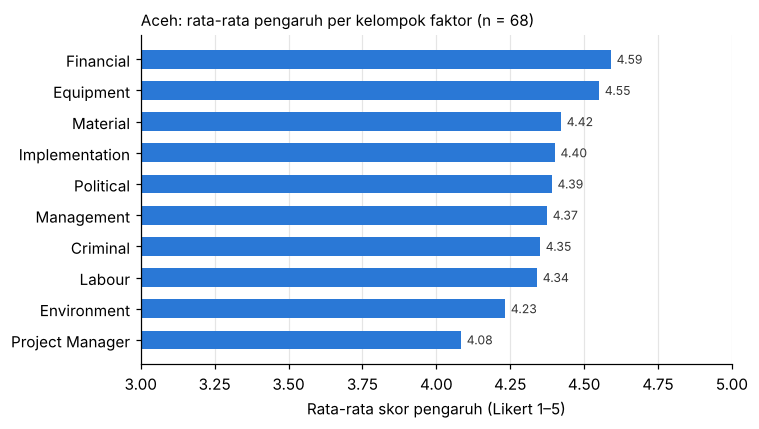

In [5]:
grp = item_stats.groupby("group")["mean"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(grp.index, grp.values, color=C_MAIN, height=0.6)
for y, v in enumerate(grp.values):
    ax.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=8, color="#333")
ax.set_xlim(3, 5)
ax.set_xlabel("Rata-rata skor pengaruh (Likert 1–5)")
ax.set_title("Aceh: rata-rata pengaruh per kelompok faktor (n = 68)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

audit_rows.append(dict(dataset="Aceh delay survey (Mendeley)", file="Dataset_1.xlsx",
    rows=len(aceh), cols=aceh.shape[1], granularity="survey (1 baris = 1 responden PM)",
    targets="Y1–Y4 (tidak terdokumentasi)", missing=int(items.isna().sum().sum()),
    empirical_or_synthetic="Empiris", recommendation="Knowledge base bobot faktor; tidak digabung"))

**Catatan Aceh**
- Data **persepsi**, bukan kejadian kendala: tidak ada delay_days, biaya, atau label risiko per kendala. Mengubah tiap responden menjadi "kejadian kendala" tidak punya dasar metodologis.
- Skor sangat tinggi dan homogen (sebagian besar 4–5). Variasi antar-item kecil, sehingga lebih cocok dipakai sebagai **ranking/bobot faktor** daripada data training.
- Kelompok faktor X1–X10 dapat dipetakan ke `kategori` Way2Home sebagai referensi `checklist_factors` yang dapat ditelusuri.

## 2. Simulated Project Risk — fitur mentah (`project_risk_raw_dataset.csv`)

In [6]:
raw = pd.read_csv(RAW / "project_risk_raw_dataset.csv")
info = profile(raw, "project_risk_raw")
display(info[info["missing"] > 0])
print("Project_Type:", raw["Project_Type"].value_counts().to_dict())
print("Risk_Level  :", raw["Risk_Level"].value_counts().to_dict())
print("\nKolom numerik yang didominasi nilai konstan:")
for c in ["Schedule_Pressure", "Technical_Debt_Level", "Seasonal_Risk_Factor"]:
    print(f"  {c}: {(raw[c] == raw[c].mode()[0]).mean():.0%} bernilai {raw[c].mode()[0]}")
display(raw.describe().T[["min", "mean", "max"]].round(2))

=== project_risk_raw: 4,000 baris × 51 kolom | duplikat baris: 0
                           dtype  missing  missing_%  n_unique
Tech_Environment_Stability   str     2619       65.5         3
Change_Control_Maturity      str      780       19.5         3
Risk_Management_Maturity     str      791       19.8         3
Project_Type: {'IT': 1381, 'Construction': 797, 'R&D': 588, 'Manufacturing': 418, 'Marketing': 418, 'Healthcare': 398}
Risk_Level  : {'Medium': 1396, 'High': 1036, 'Low': 806, 'Critical': 762}

Kolom numerik yang didominasi nilai konstan:
  Schedule_Pressure: 60% bernilai 0.0
  Technical_Debt_Level: 66% bernilai 0.0
  Seasonal_Risk_Factor: 89% bernilai 1.0
                                       min        mean         max
Team_Size                             2.00       15.39       50.00
Project_Budget_USD               159355.55  1143031.50  3768354.37
Estimated_Timeline_Months             2.00       17.15       36.00
Complexity_Score                      1.62        6.19  

In [7]:
audit_rows.append(dict(dataset="Simulated Project Risk – raw features", file="project_risk_raw_dataset.csv",
    rows=len(raw), cols=raw.shape[1], granularity="project-level (6 jenis proyek; 797 Construction)",
    targets="Risk_Level 4 kelas (Low/Medium/High/Critical)",
    missing="Tech_Environment_Stability 65%, Change_Control 20%, Risk_Mgmt 20%",
    empirical_or_synthetic="Sintetis", recommendation="Eksperimen terpisah; fitur tidak tersedia di Way2Home"))

**Catatan:** dataset bersifat lintas industri (IT, R&D, dll.). Hanya ~20% yang berjenis *Construction*. Fiturnya bersifat manajerial (turnover tim, sponsorship, dsb.) dan tidak tersedia pada input Way2Home. Ada juga kelas *Critical* yang tidak ada di skema LOW/MEDIUM/HIGH.

## 3. Simulated EV — ringkasan & deret waktu

Kedua file `.xlsx` ternyata berisi **teks CSV di satu kolom**, jadi dibaca ulang sebagai CSV.

In [8]:
ev_sum = read_csv_inside_xlsx(RAW / "project_delay_cost_overrun_summary_final.csv.xlsx")
ev_ts = read_csv_inside_xlsx(RAW / "simulated_project_ev_metrics_final.csv.xlsx")
display(profile(ev_sum, "EV summary"))
display(profile(ev_ts, "EV time series"))
print("Proyek unik di time series:", ev_ts["Project_ID"].nunique())
display(ev_sum.describe().T.round(2))

=== EV summary: 4,000 baris × 7 kolom | duplikat baris: 0
                             dtype  missing  missing_%  n_unique
Project_ID                     str        0        0.0      4000
Estimated_Timeline_Months    int64        0        0.0        35
Actual_Duration_Months       int64        0        0.0        40
Planned_Budget             float64        0        0.0      4000
Actual_Cost                float64        0        0.0      4000
Schedule_Delay               int64        0        0.0        15
Cost_Overrun               float64        0        0.0      4000
=== EV time series: 72,549 baris × 15 kolom | duplikat baris: 0
                             dtype  missing  missing_%  n_unique
Project_ID                     str        0        0.0      4000
Month                        int64        0        0.0        43
PV                         float64        0        0.0     72549
EV                         float64        0        0.0     72549
AC                         float6

### 3a. Asal-usul: apakah EV summary diturunkan dari `project_risk_raw`?

In [9]:
m = ev_sum.merge(raw[["Project_ID", "Estimated_Timeline_Months", "Project_Budget_USD", "Risk_Level"]],
                 on="Project_ID", suffixes=("_ev", "_raw"))
print("Project_ID yang cocok        :", len(m), "dari", len(ev_sum))
print("Budget identik               :", f"{np.isclose(m.Planned_Budget, m.Project_Budget_USD).mean():.0%}")
print("Timeline rencana identik     :", f"{(m.Estimated_Timeline_Months_ev == m.Estimated_Timeline_Months_raw).mean():.0%}")
print("Schedule_Delay = Actual - Est:", f"{(ev_sum.Schedule_Delay == ev_sum.Actual_Duration_Months - ev_sum.Estimated_Timeline_Months).mean():.0%}")
print("\nDistribusi Sched_Delay (bulan):", ev_sum.Schedule_Delay.value_counts().sort_index().to_dict())

Project_ID yang cocok        : 4000 dari 4000
Budget identik               : 100%
Timeline rencana identik     : 100%
Schedule_Delay = Actual - Est: 100%

Distribusi Sched_Delay (bulan): {-5: 3, -4: 4, -3: 24, -2: 103, -1: 347, 0: 1071, 1: 1187, 2: 721, 3: 312, 4: 141, 5: 54, 6: 22, 7: 7, 8: 2, 9: 2}


### 3b. Bug encoding pada skrip simulasi

`simulate_project_ev_metrics.py` memakai mapping ordinal berikut. Nilai yang **tidak ada** di mapping diubah menjadi 0 oleh `.map(...).fillna(0)`. Selain itu, `Project_Manager_Experience` dan `Org_Process_Maturity` tercantum di daftar numerik **dan** kategorikal. Konversi numerik membuat semuanya NaN, sehingga kolom tersebut menjadi konstan.

In [10]:
script_mappings = {   # disalin dari simulate_project_ev_metrics.py
    "Complexity_Score": {"Low": 1, "Medium": 2, "High": 3},
    "Team_Experience_Level": {"Junior": 1, "Mid": 2, "Senior": 3, "Lead": 4},
    "Risk_Level": {"Low": 1, "Medium": 2, "High": 3},
    "Documentation_Quality": {"Poor": 1, "Acceptable": 2, "Good": 3},
}
for col, mp in script_mappings.items():
    if raw[col].dtype == object or str(raw[col].dtype).startswith("str"):
        unmapped = raw.loc[~raw[col].isin(mp), col].value_counts()
        print(f"{col}: nilai tak terpetakan -> 0 : {unmapped.to_dict()}  ({unmapped.sum() / len(raw):.0%} baris)")
    else:
        print(f"{col}: kolom numerik, mapping kategorikal tidak dipakai")

m["delay_pct_cost"] = ev_sum.set_index("Project_ID").loc[m.Project_ID, "Cost_Overrun"].values / m.Planned_Budget
print("\nRata-rata Schedule_Delay & overrun% per Risk_Level (raw):")
display(m.groupby("Risk_Level")[["Schedule_Delay", "delay_pct_cost"]].mean().round(3))

Complexity_Score: kolom numerik, mapping kategorikal tidak dipakai
Team_Experience_Level: nilai tak terpetakan -> 0 : {'Mixed': 1593, 'Expert': 415}  (50% baris)
Risk_Level: nilai tak terpetakan -> 0 : {'Critical': 762}  (19% baris)
Documentation_Quality: nilai tak terpetakan -> 0 : {'Basic': 1392, 'Excellent': 620}  (50% baris)

Rata-rata Schedule_Delay & overrun% per Risk_Level (raw):
            Schedule_Delay  delay_pct_cost
Risk_Level                                
Critical             0.906           0.067
High                 1.086           0.064
Low                  0.942           0.053
Medium               0.991           0.058


In [11]:
for name, df_, t in [("Simulated EV – summary", ev_sum, "Schedule_Delay (bulan), Cost_Overrun (USD)"),
                     ("Simulated EV – time series", ev_ts, "sama dengan summary")]:
    audit_rows.append(dict(dataset=name, file="(csv di dalam xlsx)", rows=len(df_), cols=df_.shape[1],
        granularity="project-level" if "summary" in name else "project-month", targets=t, missing=int(df_.isna().sum().sum()),
        empirical_or_synthetic="Simulasi (dari raw via skrip)",
        recommendation="Tidak dipakai: target = rumus dari fitur + bug encoding"))

**Kesimpulan EV:** target `Schedule_Delay` dan `Cost_Overrun` adalah fungsi rumus berbobot dari fitur `project_risk_raw` ditambah noise. Model yang dilatih di sini hanya akan merekonstruksi rumus tersebut (sirkular). Karena bug encoding, proyek berlabel *Critical* malah diperlakukan sebagai risiko paling rendah. **Tidak dipakai untuk training.**

## 4. Construction Project Delay Risk Prediction (`construction_projects.csv`)

In [12]:
cp = pd.read_csv(RAW / "construction_projects.csv")
display(profile(cp, "construction_projects"))
display(cp.describe().T.round(2))

=== construction_projects: 5,000 baris × 12 kolom | duplikat baris: 0
                         dtype  missing  missing_%  n_unique
project_budget         float64        0        0.0      4995
actual_cost            float64        0        0.0      5000
budget_variance        float64        0        0.0      5000
worker_count             int64        0        0.0       106
equipment_utilization  float64        0        0.0      2895
safety_incidents         int64        0        0.0        10
material_delay_days      int64        0        0.0        34
weather_delay_days       int64        0        0.0        32
completion_percentage  float64        0        0.0      3810
project_duration_days    int64        0        0.0      1005
delay_risk                 str        0        0.0         3
delay_days               int64        0        0.0        47
                        count         mean          std          min         25%          50%          75%           max
project_budget  

### 4a. Uji kebocoran label

In [13]:
print("budget_variance == actual_cost - project_budget :",
      f"{np.isclose(cp.budget_variance, cp.actual_cost - cp.project_budget, atol=0.02).mean():.0%}")
print("\ndelay_days per kelas delay_risk:")
display(cp.groupby("delay_risk")["delay_days"].agg(["count", "min", "max", "mean"]).round(1))
rule = pd.cut(cp.delay_days, [-1, 7, 20, np.inf], labels=["Low", "Medium", "High"]).astype(str)
print("delay_risk direproduksi dari ambang 0–7 / 8–20 / ≥21 hari:", f"{(rule == cp.delay_risk).mean():.1%}")

budget_variance == actual_cost - project_budget : 100%

delay_days per kelas delay_risk:
            count  min  max  mean
delay_risk                       
High          410   21   62  26.2
Low          2660    0    7   2.4
Medium       1930    8   20  12.9
delay_risk direproduksi dari ambang 0–7 / 8–20 / ≥21 hari: 100.0%


### 4b. Indikasi data sintetis

project_duration_days vs Uniform(90, 1099): KS p = 0.530  (p besar = konsisten dengan distribusi seragam)
Proporsi delay_days = 0: 22.9%

Korelasi terhadap delay_days:
equipment_utilization   -0.164
completion_percentage   -0.119
project_budget           0.000
actual_cost              0.022
worker_count             0.199
budget_variance          0.208
weather_delay_days       0.266
project_duration_days    0.361
safety_incidents         0.424
material_delay_days      0.487


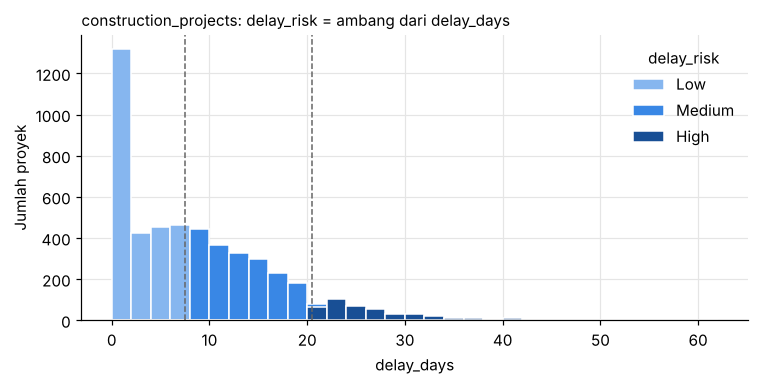

In [14]:
p = kstest((cp.project_duration_days - 90) / (1099 - 90), "uniform").pvalue
print(f"project_duration_days vs Uniform(90, 1099): KS p = {p:.3f}  (p besar = konsisten dengan distribusi seragam)")
print("Proporsi delay_days = 0:", f"{(cp.delay_days == 0).mean():.1%}")
print("\nKorelasi terhadap delay_days:")
display(cp.drop(columns="delay_risk").corr()["delay_days"].drop("delay_days").sort_values().round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.arange(0, cp.delay_days.max() + 2, 2)
for k in ["Low", "Medium", "High"]:
    ax.hist(cp.loc[cp.delay_risk == k, "delay_days"], bins=bins, color=C_ORD[k], label=k,
            edgecolor="white", linewidth=1)
ax.axvline(7.5, color="#666", lw=1, ls="--"); ax.axvline(20.5, color="#666", lw=1, ls="--")
ax.set_xlabel("delay_days"); ax.set_ylabel("Jumlah proyek")
ax.set_title("construction_projects: delay_risk = ambang dari delay_days", loc="left", fontsize=10)
ax.legend(title="delay_risk", frameon=False)
plt.tight_layout(); plt.show()

audit_rows.append(dict(dataset="Construction Project Delay Risk (GitHub)", file="construction_projects.csv",
    rows=len(cp), cols=cp.shape[1], granularity="project-level",
    targets="delay_risk (ambang delay_days), delay_days, budget_variance", missing=int(cp.isna().sum().sum()),
    empirical_or_synthetic="Sintetis (tanpa dokumentasi; distribusi seragam)",
    recommendation="Kandidat utama risk & delay (subset terpisah)"))

**Catatan:** `delay_risk` adalah turunan langsung dari `delay_days`, jadi **`delay_days` harus dikeluarkan** dari fitur saat memprediksi risiko. Begitu pula `actual_cost` dan `budget_variance` untuk target biaya. Label tetap sah sebagai label berbasis *outcome*.

## 5. BIM AI Civil Engineering (`bim_ai_civil_engineering_dataset.csv`)

In [15]:
bim = pd.read_csv(RAW / "bim_ai_civil_engineering_dataset.csv")
display(profile(bim, "BIM AI"))
for c in ["Project_Type", "Location", "Weather_Condition", "Risk_Level", "Anomaly_Detected"]:
    print(f"{c}: {bim[c].value_counts().to_dict()}")

=== BIM AI: 1,000 baris × 28 kolom | duplikat baris: 0
                         dtype  missing  missing_%  n_unique
Project_ID                 str        0        0.0      1000
Project_Type               str        0        0.0         5
Location                   str        0        0.0         5
Start_Date                 str        0        0.0      1000
End_Date                   str        0        0.0       691
Planned_Cost             int64        0        0.0      1000
Actual_Cost            float64        0        0.0      1000
Cost_Overrun           float64        0        0.0      1000
Planned_Duration         int64        0        0.0       546
Actual_Duration        float64        0        0.0      1000
Schedule_Deviation     float64        0        0.0      1000
Vibration_Level        float64        0        0.0      1000
Crack_Width            float64        0        0.0      1000
Load_Bearing_Capacity  float64        0        0.0      1000
Temperature            float64

### 5a. Identitas aritmetika & konsistensi tanggal

In [16]:
print("Cost_Overrun == Actual - Planned        :", f"{np.isclose(bim.Cost_Overrun, bim.Actual_Cost - bim.Planned_Cost).mean():.0%}")
print("Schedule_Deviation == Actual - Planned  :", f"{np.isclose(bim.Schedule_Deviation, bim.Actual_Duration - bim.Planned_Duration).mean():.0%}")
sd, ed = pd.to_datetime(bim.Start_Date), pd.to_datetime(bim.End_Date)
print("Start_Date naik tepat 1 hari per baris  :", f"{(sd.diff().dt.days.dropna() == 1).mean():.0%}")
print("(End - Start) - Planned_Duration [hari] :", ((ed - sd).dt.days - bim.Planned_Duration).describe()[["min", "50%", "max"]].round(0).to_dict())
print("(End - Start) - Actual_Duration  [hari] :", ((ed - sd).dt.days - bim.Actual_Duration).describe()[["min", "50%", "max"]].round(0).to_dict())

Cost_Overrun == Actual - Planned        : 100%
Schedule_Deviation == Actual - Planned  : 100%
Start_Date naik tepat 1 hari per baris  : 100%
(End - Start) - Planned_Duration [hari] : {'min': -668.0, '50%': 14.0, 'max': 679.0}
(End - Start) - Actual_Duration  [hari] : {'min': -1090.0, '50%': -86.0, 'max': 669.0}


### 5b. Apakah target punya sinyal, atau dibangkitkan acak?

Rasio biaya  : 0.900–1.500 | KS vs Uniform p = 0.625
Rasio durasi : 0.900–1.499 | KS vs Uniform p = 0.532
Korelasi |r| maksimum antar fitur sensor/K3/lingkungan: 0.099  (≈ independen)


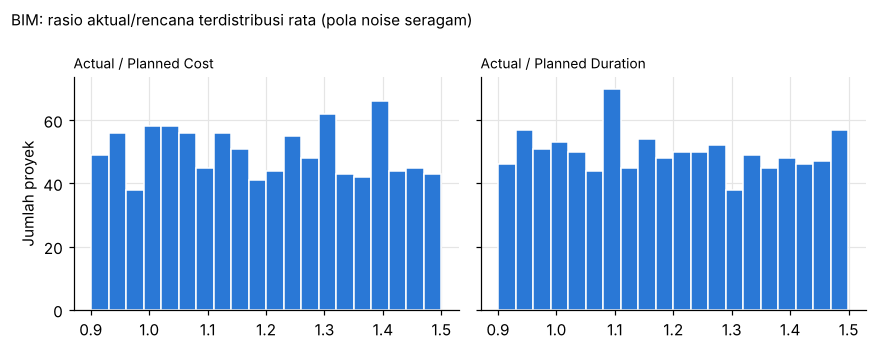

In [17]:
cost_ratio = bim.Actual_Cost / bim.Planned_Cost
dur_ratio = bim.Actual_Duration / bim.Planned_Duration
print(f"Rasio biaya  : {cost_ratio.min():.3f}–{cost_ratio.max():.3f} | KS vs Uniform p = {kstest((cost_ratio - 0.9) / 0.6, 'uniform').pvalue:.3f}")
print(f"Rasio durasi : {dur_ratio.min():.3f}–{dur_ratio.max():.3f} | KS vs Uniform p = {kstest((dur_ratio - 0.9) / 0.6, 'uniform').pvalue:.3f}")
feat_num = bim.select_dtypes("number").drop(columns=["Planned_Cost", "Actual_Cost", "Cost_Overrun",
                                                       "Planned_Duration", "Actual_Duration", "Schedule_Deviation"])
cm = np.array(feat_num.corr().abs().values); np.fill_diagonal(cm, 0)
print(f"Korelasi |r| maksimum antar fitur sensor/K3/lingkungan: {cm.max():.3f}  (≈ independen)")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, r, t in [(axes[0], cost_ratio, "Actual / Planned Cost"), (axes[1], dur_ratio, "Actual / Planned Duration")]:
    ax.hist(r, bins=20, color=C_MAIN, edgecolor="white", linewidth=1)
    ax.set_title(t, loc="left", fontsize=9)
axes[0].set_ylabel("Jumlah proyek")
fig.suptitle("BIM: rasio aktual/rencana terdistribusi rata (pola noise seragam)", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

### 5c. Asal label `Risk_Level`

In [18]:
pvals = {c: f_oneway(*[g[c].values for _, g in bim.groupby("Risk_Level")]).pvalue for c in feat_num.columns}
print("ANOVA p-value fitur vs Risk_Level (p < 0.05):", {k: round(v, 4) for k, v in pvals.items() if v < 0.05})
for c in ["Project_Type", "Location", "Weather_Condition"]:
    print(f"chi2 {c} vs Risk_Level: p = {chi2_contingency(pd.crosstab(bim[c], bim.Risk_Level))[1]:.3f}")

X2 = bim[["Safety_Risk_Score", "Anomaly_Detected"]]
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X2, bim.Risk_Level)
print(f"\nPohon keputusan 2 fitur (depth 3) mereproduksi Risk_Level: {tree.score(X2, bim.Risk_Level):.1%}")
print(export_text(tree, feature_names=list(X2.columns)))

audit_rows.append(dict(dataset="BIM AI Civil Engineering (GitHub)", file="bim_ai_civil_engineering_dataset.csv",
    rows=len(bim), cols=bim.shape[1], granularity="project-level (infrastruktur besar AS)",
    targets="Risk_Level, Cost_Overrun, Schedule_Deviation", missing=int(bim.isna().sum().sum()),
    empirical_or_synthetic="Sintetis",
    recommendation="Tidak layak: label = aturan Safety_Risk_Score+Anomaly; target biaya/waktu acak"))

ANOVA p-value fitur vs Risk_Level (p < 0.05): {'Safety_Risk_Score': np.float64(0.0), 'Anomaly_Detected': np.float64(0.0)}
chi2 Project_Type vs Risk_Level: p = 0.972
chi2 Location vs Risk_Level: p = 0.273
chi2 Weather_Condition vs Risk_Level: p = 0.332

Pohon keputusan 2 fitur (depth 3) mereproduksi Risk_Level: 93.6%
|--- Safety_Risk_Score <= 5.76
|   |--- Safety_Risk_Score <= 2.53
|   |   |--- Anomaly_Detected <= 0.50
|   |   |   |--- class: Low
|   |   |--- Anomaly_Detected >  0.50
|   |   |   |--- class: Medium
|   |--- Safety_Risk_Score >  2.53
|   |   |--- Anomaly_Detected <= 0.50
|   |   |   |--- class: Medium
|   |   |--- Anomaly_Detected >  0.50
|   |   |   |--- class: High
|--- Safety_Risk_Score >  5.76
|   |--- Safety_Risk_Score <= 5.98
|   |   |--- Safety_Risk_Score <= 5.95
|   |   |   |--- class: High
|   |   |--- Safety_Risk_Score >  5.95
|   |   |   |--- class: Medium
|   |--- Safety_Risk_Score >  5.98
|   |   |--- class: High



**Kesimpulan BIM:** `Risk_Level` hampir sepenuhnya merupakan aturan dari `Safety_Risk_Score` dan `Anomaly_Detected`. Akurasi ~97% di notebook asli hanya mempelajari ulang aturan itu. Rasio biaya dan durasi aktual/rencana seragam serta tidak berhubungan dengan fitur, dan `End_Date` tidak konsisten dengan durasi. **Tidak layak untuk training.**

## 6. Construction Delay Prediction — synthetic, Aljazair (`synthetic_construction_projects.csv`)

In [19]:
alg = pd.read_csv(RAW / "synthetic_construction_projects.csv")
display(profile(alg, "synthetic_construction_projects"))
print("Delay_Risk:", alg.Delay_Risk.value_counts().to_dict())
rows = []
for c in ["Project_Type", "Region", "Material_Availability", "Equipment_Availability",
          "Weather_Risk", "Supplier_Delay", "Project_Complexity"]:
    ct = pd.crosstab(alg[c], alg.Delay_Risk)
    rows.append({"fitur": c, "kategori": alg[c].nunique(), "chi2_p": chi2_contingency(ct)[1]})
display(pd.DataFrame(rows).round(4))
display(alg.groupby("Delay_Risk")[["Planned_Duration_Months", "Project_Progress_Percent", "Cost_Used_Percent",
                                    "Number_of_Workers", "Safety_Incidents"]].mean().round(2))
audit_rows.append(dict(dataset="Construction Delay Prediction (Aljazair, synthetic)", file="synthetic_construction_projects.csv",
    rows=len(alg), cols=alg.shape[1], granularity="project-level", targets="Delay_Risk biner (Yes/No)",
    missing=int(alg.isna().sum().sum()), empirical_or_synthetic="Sintetis (dinyatakan)",
    recommendation="Opsional: klasifikasi biner terpisah"))

=== synthetic_construction_projects: 1,000 baris × 15 kolom | duplikat baris: 0
                            dtype  missing  missing_%  n_unique
Project_ID                    str        0        0.0      1000
Project_Type                  str        0        0.0         6
Region                        str        0        0.0        12
Planned_Duration_Months     int64        0        0.0        43
Project_Progress_Percent    int64        0        0.0        96
Budget_Million_DZD        float64        0        0.0      1000
Cost_Used_Percent         float64        0        0.0       964
Number_of_Workers           int64        0        0.0       566
Material_Availability         str        0        0.0         3
Equipment_Availability        str        0        0.0         3
Weather_Risk                  str        0        0.0         3
Supplier_Delay                str        0        0.0         2
Project_Complexity            str        0        0.0         3
Safety_Incidents        

**Catatan:** target hanya biner (tanpa delay_days maupun biaya aktual). Faktor material, alat, cuaca, pemasok, dan kompleksitas berasosiasi kuat dengan target. Secara makna, faktor-faktor ini paling dekat dengan `kategori` kendala Way2Home.

## 7. RCPLIB (`RCPLIB__Parameters_and_BKS_.xlsx`)

Brief menyebut **DSLIB/PSLIB**, tetapi file yang diunggah adalah **RCPLIB**: kumpulan instance RCPSP buatan generator untuk benchmark algoritma penjadwalan.

In [20]:
import openpyxl
wb = openpyxl.load_workbook(RAW / "RCPLIB__Parameters_and_BKS_.xlsx", read_only=True)
sheets = pd.DataFrame([{"sheet": ws.title, "rows": ws.max_row, "cols": ws.max_column} for ws in wb.worksheets])
display(sheets)
hdr = next(wb["All"].iter_rows(min_row=1, max_row=1, values_only=True))
print("Contoh kolom sheet 'All':", hdr[:30])
wb.close()
audit_rows.append(dict(dataset="RCPLIB (bukan DSLIB)", file="RCPLIB__Parameters_and_BKS_.xlsx",
    rows=int(sheets.loc[sheets.sheet == "All", "rows"].iloc[0]) - 1, cols=int(sheets.loc[sheets.sheet == "All", "cols"].iloc[0]),
    granularity="instance-level (jaringan jadwal buatan)", targets="best-known makespan (bukan keterlambatan aktual)",
    missing="n/a", empirical_or_synthetic="Benchmark artifisial", recommendation="Tidak relevan untuk 3 target"))

                 sheet   rows  cols
0             Overview     75    13
1   Parameter Overview    417    18
2                  All  13575   410
3                   DC   2521   410
4                   CV    624   410
5               PSPLIB   2041   410
6                 RG30   1801   410
7             1kNetRes   3811   410
8                   sD    391   410
9                   MH    462     8
10               RG300    481   410
11                 VNR   1751   410
12                 LPP     81   410
13                LPSP     82   410
Contoh kolom sheet 'All': ('ID', 'ID set', 'SetName', 'SubSet', 'FileName', '#Act', 'CNC', 'OS', 'SP', 'AD', 'LA', 'I5', 'TF', 'Wprec', 'Wall', 'FS21', 'FS22', 'FS31', 'FS32', 'l', 'f', 'LE', 'FE', '#R', 'RF', 'RU', 'RS', 'RC', '#lR', 'lRF')


Indikator jaringan (CNC, OS, SP, …) dan resource (RF, RU, RS, RC) tidak memiliki padanan dengan kendala lapangan. Selain itu tidak ada outcome keterlambatan maupun biaya aktual. **Tidak relevan.**

## 8. Uji sinyal target (cross-validation cepat, tanpa leakage)

Ini **bukan training final**. Tujuannya mengecek apakah target masih bisa dipelajari setelah kolom bocor dikeluarkan. Model: Random Forest dengan 5-fold CV.

In [21]:
def rf_reg(): return RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED)
def rf_clf(): return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED); skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
res = []

Xcp = cp.drop(columns=["delay_days", "delay_risk", "actual_cost", "budget_variance"])
res.append(("construction_projects", "delay_days", "R²", cross_val_score(rf_reg(), Xcp, cp.delay_days, cv=kf, scoring="r2").mean()))
res.append(("construction_projects", "delay_risk (L/M/H)", "macro-F1", cross_val_score(rf_clf(), Xcp, cp.delay_risk, cv=skf, scoring="f1_macro").mean()))
res.append(("construction_projects", "cost overrun %", "R²", cross_val_score(rf_reg(), Xcp, cp.budget_variance / cp.project_budget, cv=kf, scoring="r2").mean()))

Xb = pd.get_dummies(bim.drop(columns=["Project_ID", "Start_Date", "End_Date", "Actual_Cost", "Cost_Overrun",
                                      "Actual_Duration", "Schedule_Deviation", "Risk_Level"]), dtype=int)
res.append(("BIM", "schedule deviation ratio", "R²", cross_val_score(rf_reg(), Xb, dur_ratio, cv=kf, scoring="r2").mean()))
res.append(("BIM", "cost overrun %", "R²", cross_val_score(rf_reg(), Xb, cost_ratio - 1, cv=kf, scoring="r2").mean()))

Xa = pd.get_dummies(alg.drop(columns=["Project_ID", "Delay_Risk"]), dtype=int)
res.append(("Aljazair", "Delay_Risk (biner)", "macro-F1", cross_val_score(rf_clf(), Xa, alg.Delay_Risk, cv=skf, scoring="f1_macro").mean()))

Xr = pd.get_dummies(raw.drop(columns=["Project_ID", "Risk_Level"]), dtype=int)
res.append(("project_risk_raw", "Risk_Level (4 kelas)", "macro-F1", cross_val_score(rf_clf(), Xr, raw.Risk_Level, cv=skf, scoring="f1_macro").mean()))

signal = pd.DataFrame(res, columns=["dataset", "target", "metrik", "skor_CV"]).round(3)
display(signal)
signal.to_csv(REPORTS / "00_target_signal_check.csv", index=False)

                 dataset                    target    metrik  skor_CV
0  construction_projects                delay_days        R²    0.544
1  construction_projects        delay_risk (L/M/H)  macro-F1    0.597
2  construction_projects            cost overrun %        R²    0.004
3                    BIM  schedule deviation ratio        R²   -0.047
4                    BIM            cost overrun %        R²   -0.038
5               Aljazair        Delay_Risk (biner)  macro-F1    0.717
6       project_risk_raw      Risk_Level (4 kelas)  macro-F1    0.552


Interpretasi:
- `construction_projects`: delay_days dan delay_risk punya sinyal sedang. **Cost overrun ≈ 0**, artinya tidak ada sinyal.
- BIM: rasio biaya dan durasi ≈ 0 atau negatif, sesuai temuan bahwa targetnya noise acak.
- Tidak ada satu pun dataset **empiris** dengan outcome waktu atau biaya. Karena itu validasi "empiris vs sintetis" untuk regresi tidak dapat dilakukan.

## 9. Pemetaan semantik ke input `ai-kendala.service.ts`

In [22]:
mapping = pd.DataFrame([
    ("kategori", "Aceh X1–X10 (kelompok faktor); construction_projects material/weather delay & safety_incidents; Aljazair Material/Equipment/Weather/Supplier", "Sedang — perlu enum kategori Way2Home"),
    ("deskripsi", "—", "Tidak ada padanan (tidak ada teks bebas)"),
    ("kondisi_pekerjaan", "—", "Tidak ada padanan"),
    ("dampak_waktu_hari", "construction_projects material_delay_days, weather_delay_days", "Lemah–sedang: agregat proyek, bukan per kendala"),
    ("informasi_tambahan", "—", "Tidak ada padanan"),
    ("nama_tahap", "project_risk_raw Project_Phase (Initiation/Planning/Execution…)", "Lemah: bukan tahap konstruksi rumah"),
    ("judul_subtask", "—", "Tidak ada padanan"),
    ("bobot_subtask", "—", "Tidak ada padanan"),
    ("nama_desain", "—", "Tidak ada padanan"),
    ("status_proyek", "construction_projects completion_percentage; Aljazair Project_Progress_Percent", "Lemah: perlu enum status Way2Home"),
], columns=["input_way2home", "padanan_di_dataset_eksternal", "kualitas_padanan"])
display(mapping)
mapping.to_csv(REPORTS / "00_way2home_input_mapping.csv", index=False)

       input_way2home                                                                                                                  padanan_di_dataset_eksternal                                 kualitas_padanan
0            kategori  Aceh X1–X10 (kelompok faktor); construction_projects material/weather delay & safety_incidents; Aljazair Material/Equipment/Weather/Supplier            Sedang — perlu enum kategori Way2Home
1           deskripsi                                                                                                                                             —         Tidak ada padanan (tidak ada teks bebas)
2   kondisi_pekerjaan                                                                                                                                             —                                Tidak ada padanan
3   dampak_waktu_hari                                                                                 construction_projects material_delay_days, wea

## 10. Tabel audit akhir

In [23]:
audit = pd.DataFrame(audit_rows)
display(audit)
audit.to_csv(REPORTS / "00_dataset_audit_table.csv", index=False)
print("Tersimpan:", sorted(p.name for p in REPORTS.glob("00_*.csv")))

                                               dataset                                  file   rows  cols                                       granularity                                                      targets                                                            missing                            empirical_or_synthetic                                                                  recommendation
0                         Aceh delay survey (Mendeley)                        Dataset_1.xlsx     68    65                 survey (1 baris = 1 responden PM)                                 Y1–Y4 (tidak terdokumentasi)                                                                  0                                           Empiris                                     Knowledge base bobot faktor; tidak digabung
1                Simulated Project Risk – raw features          project_risk_raw_dataset.csv   4000    51  project-level (6 jenis proyek; 797 Construction)                R

## 11. Kesimpulan & rekomendasi

1. **Tidak ada dataset issue-level.** Semua sumber berbentuk survei atau per-proyek. Menggabungkan semuanya menjadi "1 baris = 1 kendala" tidak valid.
2. **Kandidat training:** `construction_projects` untuk `risk_level` dan `delay_days` (setelah kolom bocor dikeluarkan); `synthetic_construction_projects` (Aljazair) sebagai klasifikasi biner terpisah.
3. **Knowledge base:** survei Aceh menjadi dasar ranking faktor untuk `checklist_factors` yang dapat ditelusuri.
4. **`cost_overrun` tidak dilatih**: tidak ada sumber dengan sinyal maupun definisi yang konsisten.
5. **Dikeluarkan:** EV simulasi (sirkular + bug encoding), BIM (label berbasis aturan, target acak), RCPLIB (tidak relevan).
6. Fitur penting di `construction_projects` (budget, pekerja, utilisasi alat, durasi) tidak tersedia di input Way2Home. Desain fitur di `02_data_harmonization.ipynb` harus memisahkan varian **"Way2Home-compatible features"** dan **"full features"**.

**Sumber:**
- Rauzana, A., & Dharma, W. (2022). Causes of delays in construction projects in the Province of Aceh, Indonesia. *PLOS ONE*, 17(1), e0263337. https://pmc.ncbi.nlm.nih.gov/articles/PMC8797244
- Dataset Aceh: https://data.mendeley.com/datasets/2wckhrzz5j/1